# 03 - Model Training Pipeline (Linear Regression)

**Goal:** train one Linear Regression model for each dataset using a complete, repeatable scikit-learn pipeline, measure how good it is, and save it for the Gradio and Flask apps.

**Pipeline for every model**

```
raw input row
   |
   v
ColumnTransformer
   |-- category columns  -> OneHotEncoder   (Species)
   |-- number columns    -> StandardScaler  (all measurements)
   |
   v
LinearRegression
   |
   v
prediction
```

Putting the preprocessing *inside* the pipeline means the exact same steps run during training and when the web apps predict, so there is no mismatch.

**Evaluation plan:** 80% train / 20% test split, 5-fold cross-validation on the training part, and final scores on the untouched test part.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 90

RANDOM_STATE = 42
TEST_SIZE = 0.2
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

## Helper functions

In [2]:
def build_pipeline(num_cols, cat_cols):
    """Preprocessing + Linear Regression in a single object."""
    transformers = [("num", StandardScaler(), num_cols)]
    if cat_cols:
        transformers.insert(0, ("cat", OneHotEncoder(drop="first"), cat_cols))
    pre = ColumnTransformer(transformers)
    return Pipeline([("prep", pre), ("model", LinearRegression())])


def score(y_true, y_pred):
    return {
        "r2": round(float(r2_score(y_true, y_pred)), 4),
        "mae": round(float(mean_absolute_error(y_true, y_pred)), 2),
        "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 2),
    }


def plot_results(y_true, y_pred, target, unit):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    lo, hi = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    axes[0].scatter(y_true, y_pred, alpha=0.7)
    axes[0].plot([lo, hi], [lo, hi], "r--", label="perfect prediction")
    axes[0].set_xlabel(f"Actual {target} ({unit})")
    axes[0].set_ylabel(f"Predicted {target} ({unit})")
    axes[0].set_title("Actual vs predicted (test set)")
    axes[0].legend()

    resid = y_true - y_pred
    axes[1].scatter(y_pred, resid, alpha=0.7)
    axes[1].axhline(0, color="r", linestyle="--")
    axes[1].set_xlabel(f"Predicted {target} ({unit})")
    axes[1].set_ylabel("Residual (actual - predicted)")
    axes[1].set_title("Residuals (test set)")
    plt.tight_layout()
    plt.show()


def coefficient_table(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    names = [n.split("__", 1)[1] for n in names]
    coefs = pipe.named_steps["model"].coef_
    table = pd.DataFrame({"feature": names, "coefficient": coefs})
    table["abs"] = table["coefficient"].abs()
    return table.sort_values("abs", ascending=False).drop(columns="abs").reset_index(drop=True).round(3)


def feature_specs(X, cat_cols):
    """Describe every input (type, allowed values / typical range, default) - used by the web apps."""
    specs = []
    for c in X.columns:
        if c in cat_cols:
            specs.append({"name": c, "kind": "category",
                          "choices": sorted(X[c].unique().tolist()),
                          "default": X[c].mode()[0]})
        else:
            specs.append({"name": c, "kind": "number",
                          "min": round(float(X[c].min()), 2),
                          "max": round(float(X[c].max()), 2),
                          "default": round(float(X[c].median()), 2)})
    return specs

# Part A - Fish Market: predict `Weight` (grams)

In [3]:
fish = pd.read_csv("data/processed/fish_clean.csv")
FISH_TARGET = "Weight"
FISH_CAT = ["Species"]
FISH_NUM = ["Length1", "Length2", "Length3", "Height", "Width"]

X = fish[FISH_CAT + FISH_NUM]
y = fish[FISH_TARGET]

# stratify by species so every species appears in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=fish["Species"]
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("\nSpecies in test set:")
print(X_test["Species"].value_counts().to_dict())

Train rows: 126 | Test rows: 32

Species in test set:
{'Perch': 11, 'Bream': 7, 'Roach': 4, 'Pike': 4, 'Smelt': 3, 'Parkki': 2, 'Whitefish': 1}


In [4]:
fish_pipe = build_pipeline(FISH_NUM, FISH_CAT)
fish_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

### Cross-validation (training data only)

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fish_cv = cross_validate(fish_pipe, X_train, y_train, cv=cv,
                     scoring=["r2", "neg_mean_absolute_error"])
print("5-fold CV R2 per fold :", fish_cv["test_r2"].round(3))
print("Mean CV R2            :", fish_cv["test_r2"].mean().round(3), "+/-", fish_cv["test_r2"].std().round(3))
print("Mean CV MAE (grams)   :", (-fish_cv["test_neg_mean_absolute_error"]).mean().round(1))

5-fold CV R2 per fold : [0.926 0.866 0.953 0.871 0.916]
Mean CV R2            : 0.907 +/- 0.033
Mean CV MAE (grams)   : 66.8


### Fit on the training set and evaluate

In [6]:
fish_pipe.fit(X_train, y_train)

pred_train = fish_pipe.predict(X_train)
pred_test_raw = fish_pipe.predict(X_test)
print("Smallest raw prediction on test set:", pred_test_raw.min().round(1), "g")

# A fish cannot weigh less than 0 g, so we clip predictions at 0
pred_test = np.clip(pred_test_raw, 0, None)

fish_train_scores = score(y_train, np.clip(pred_train, 0, None))
fish_test_scores = score(y_test, pred_test)
pd.DataFrame({"train": fish_train_scores, "test": fish_test_scores})

Smallest raw prediction on test set: -191.5 g


,train,test
r2,0.9526,0.9401
mae,51.6800,66.4900
rmse,72.2700,107.3700


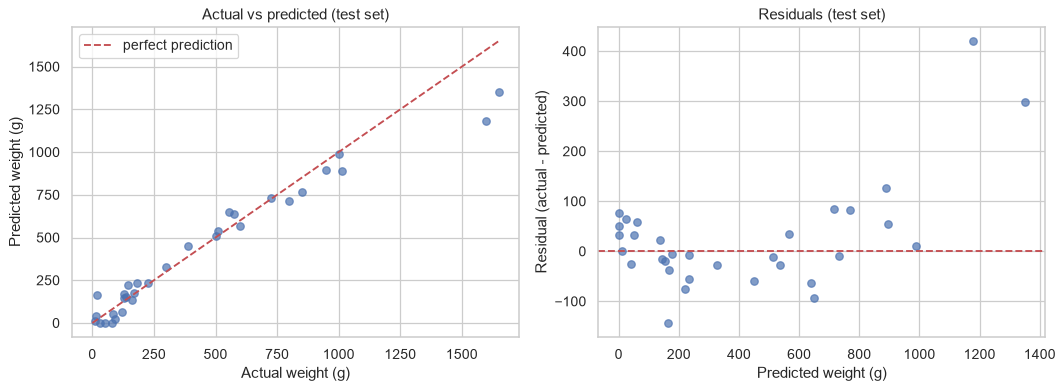

In [7]:
plot_results(y_test, pred_test, 'weight', 'g')

### What the model learned (coefficients)

In [8]:
print("Intercept:", round(fish_pipe.named_steps["model"].intercept_, 1))
coefficient_table(fish_pipe)

Intercept: 299.1


,feature,coefficient
0,Length2,827.683
1,Length1,-645.209
2,Species_Smelt,449.224
3,Length3,132.586
4,Species_Parkki,124.779
5,Species_Perch,117.078
6,Species_Pike,-106.990
7,Species_Roach,101.595
8,Species_Whitefish,76.895
9,Height,71.368


Numeric inputs were standardised, so their coefficients show the change in weight (grams) for a one-standard-deviation increase in that measurement. Species coefficients show the shift relative to the reference species (Bream, the first alphabetically).

### How to read the Fish results

- **Accuracy:** test R² is 0.94, so the model explains about 94% of the variation in fish weight. The typical error (MAE) is about 66 g, on fish that average about 400 g.
- **Not a lucky split:** cross-validation gives 0.91 (+/- 0.03), close to the test score, and train (0.95) is close to test (0.94), so there is no serious overfitting. The test set is small (32 fish), so treat the exact numbers as approximate.
- **Negative predictions:** for the smallest fish the raw line predicts a negative weight (as low as about -190 g). A straight line cannot bend down towards zero like the real curve in the EDA. We clip predictions at 0 g, and the web apps do the same.
- **Odd coefficients:** `Length1` (negative) and `Length2` (positive) are large and have opposite signs. This is the multicollinearity found in the EDA: the two columns are near-copies, so the model splits one length effect between them in a way that cancels out. Together they act as one "length" signal, so do not interpret them separately. The big positive `Species_Smelt` value similarly corrects for tiny fish, where the line would otherwise go negative.
- **Limits:** only 158 fish, and just 6 Whitefish (1 in the test set), so predictions for rare species are less reliable. Adding squared or log terms would capture the curve better, but that goes beyond plain linear regression.

# Part B - Body Fat: predict `BodyFat` (%)

In [9]:
bf = pd.read_csv("data/processed/bodyfat_clean.csv")
BF_TARGET = "BodyFat"
BF_NUM = [c for c in bf.columns if c != BF_TARGET]

Xb = bf[BF_NUM]
yb = bf[BF_TARGET]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print("Features:", BF_NUM)
print("Train rows:", len(Xb_train), "| Test rows:", len(Xb_test))

Features: ['Age', 'Weight', 'Height', 'Neck', 'Chest', 'Abdomen', 'Hip', 'Thigh', 'Knee', 'Ankle', 'Biceps', 'Forearm', 'Wrist']
Train rows: 197 | Test rows: 50


In [10]:
bf_pipe = build_pipeline(BF_NUM, cat_cols=[])
bf_cv = cross_validate(bf_pipe, Xb_train, yb_train, cv=cv,
                     scoring=["r2", "neg_mean_absolute_error"])
print("5-fold CV R2 per fold :", bf_cv["test_r2"].round(3))
print("Mean CV R2            :", bf_cv["test_r2"].mean().round(3), "+/-", bf_cv["test_r2"].std().round(3))
print("Mean CV MAE (% points):", (-bf_cv["test_neg_mean_absolute_error"]).mean().round(2))

5-fold CV R2 per fold : [0.786 0.73  0.727 0.703 0.482]
Mean CV R2            : 0.685 +/- 0.105
Mean CV MAE (% points): 3.74


In [11]:
bf_pipe.fit(Xb_train, yb_train)

bf_pred_train = np.clip(bf_pipe.predict(Xb_train), 0, None)
bf_pred_test = np.clip(bf_pipe.predict(Xb_test), 0, None)

bf_train_scores = score(yb_train, bf_pred_train)
bf_test_scores = score(yb_test, bf_pred_test)
pd.DataFrame({"train": bf_train_scores, "test": bf_test_scores})

,train,test
r2,0.7515,0.6483
mae,3.4500,3.5900
rmse,4.1800,4.5800


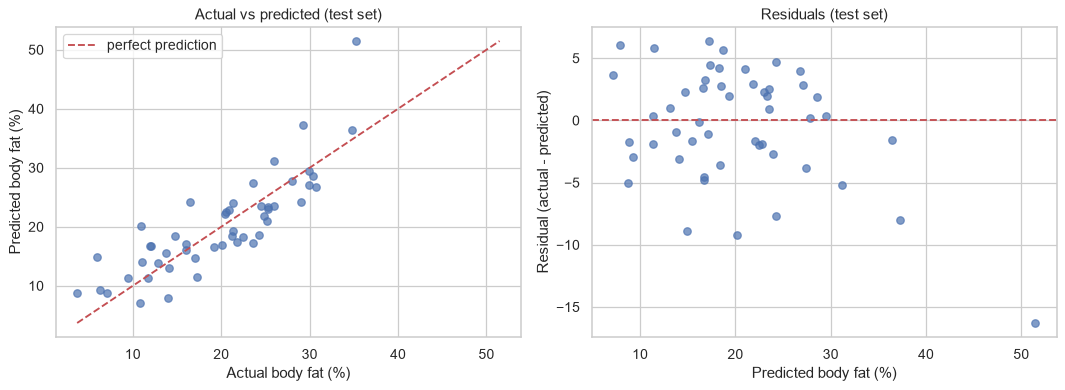

In [12]:
plot_results(yb_test, bf_pred_test, 'body fat', '%')

In [13]:
print("Intercept:", round(bf_pipe.named_steps["model"].intercept_, 2))
coefficient_table(bf_pipe)

Intercept: 19.1


,feature,coefficient
0,Abdomen,9.700
1,Wrist,-1.918
2,Chest,-1.062
3,Hip,-1.005
4,Weight,-0.927
5,Age,0.775
6,Biceps,0.685
7,Thigh,0.599
8,Forearm,0.567
9,Height,-0.519


Coefficients are per one-standard-deviation increase (inputs were standardised), so they can be compared with each other.

### How to read the Body Fat results

- **Accuracy:** test R² is 0.65, so the model explains about 65% of the variation in body fat. The typical error (MAE) is about 3.6 percentage points (RMSE 4.6). That is reasonable for a simple linear model that only sees tape measurements, but it is not precise enough for medical use.
- **Why the scores wobble:** cross-validation averages 0.69, but one fold scored only 0.48. With about 200 training rows, the result depends on which men land in each split. Train R² (0.75) being higher than test (0.65) shows mild overfitting, which is normal with 13 overlapping features and few rows. The test set has only 50 men.
- **`Abdomen` dominates:** one standard deviation more waist adds about 9.7 percentage points of body fat, far more than any other feature (matches the EDA).
- **Negative coefficients:** `Chest`, `Hip` and `Weight` come out negative even though each correlates positively with body fat on its own. They overlap heavily with `Abdomen`, so the model uses them as small corrections. Read them as adjustments, not as "bigger chest means less fat". `Wrist` being negative is plausible: for the same weight, a larger bone frame means less fat.
- **Limits:** a small dataset of 247 adult men, so it should not be used for women, children or different populations.

# Part C - Compare and save

In [14]:
comparison = pd.DataFrame({
    "Fish Market (Weight, g)": fish_test_scores,
    "Body Fat (BodyFat, %)": bf_test_scores,
}).T
comparison.columns = ["R2", "MAE", "RMSE"]
comparison

,R2,MAE,RMSE
"Fish Market (Weight, g)",0.9401,66.49,107.37
"Body Fat (BodyFat, %)",0.6483,3.59,4.58


In [15]:
# Save the two fitted pipelines and a small JSON file that describes their inputs and scores.
joblib.dump(fish_pipe, MODEL_DIR / "fish_model.joblib")
joblib.dump(bf_pipe, MODEL_DIR / "bodyfat_model.joblib")

info = {
    "fish": {
        "model_file": "fish_model.joblib",
        "target": FISH_TARGET,
        "features": feature_specs(X, FISH_CAT),
        "metrics": {**fish_test_scores, "cv_r2": round(float(fish_cv["test_r2"].mean()), 4),
                    "n_train": len(X_train), "n_test": len(X_test)},
    },
    "bodyfat": {
        "model_file": "bodyfat_model.joblib",
        "target": BF_TARGET,
        "features": feature_specs(Xb, []),
        "metrics": {**bf_test_scores, "cv_r2": round(float(bf_cv["test_r2"].mean()), 4),
                    "n_train": len(Xb_train), "n_test": len(Xb_test)},
    },
}
(MODEL_DIR / "model_info.json").write_text(json.dumps(info, indent=2))
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))

Saved: ['bodyfat_model.joblib', 'fish_model.joblib', 'model_info.json']


### Check: reload the saved model and predict one new row

In [16]:
loaded = joblib.load(MODEL_DIR / "fish_model.joblib")
example = pd.DataFrame([{"Species": "Perch", "Length1": 25.0, "Length2": 27.5, "Length3": 29.0, "Height": 7.2, "Width": 4.3}])
print("Perch, ~27 cm  ->  predicted weight:", round(float(np.clip(loaded.predict(example)[0], 0, None)), 1), "g")

loaded_bf = joblib.load(MODEL_DIR / "bodyfat_model.joblib")
row = Xb.median().to_frame().T
print("Median man     ->  predicted body fat:", round(float(np.clip(loaded_bf.predict(row)[0], 0, None)), 1), "%")

Perch, ~27 cm  ->  predicted weight: 366.7 g
Median man     ->  predicted body fat: 17.7 %


## Summary

- Both models are full pipelines (encode -> scale -> linear regression) saved with `joblib`.
- `models/model_info.json` stores each model's input fields, typical ranges and test scores. The Gradio app and the Flask app read it so their forms always match the trained models.
- Next: run `python gradio_app.py` and `python flask_app.py`.